*CS 545 final project · Ian Fisk, Ryan Baldwin · draft section for `finalreport.ipynb`. In the report it goes after the sliding-window section, since it refers to look-back windows of length $L$ and forecast horizons of length $T$.*

# Splitting time series data, and distribution shift

With ordinary supervised learning we shuffle the examples and split them at random, so the training, validation and test sets come from the same distribution. Time series break both halves of that recipe:

- **Examples overlap.** Neighbouring windows share almost all of their time steps, so a random split puts nearly identical examples on both sides.
- **The distribution moves.** Seasons, trends and one-off changes mean the future need not look like the past.

This section looks at how the papers split their data, what that does to the test set, and what the alternatives cost.

In [1]:
# render figures as crisp vector graphics (SVG) in the notebook
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

import sys
import warnings
sys.path.append("..")          # src/, where the shared data loader lives

# NumPy 2.5 warns inside pandas' date arithmetic; it is not about our code.
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import ConnectionPatch, Rectangle
from IPython.display import HTML

from ltsf_data import load

# render animations as inline HTML players
plt.rcParams['animation.html'] = 'jshtml'
plt.rcParams['animation.embed_limit'] = 40  # MB

# colors and style shared by every figure in this section
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
SURFACE = "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # one color per channel or model
HILITE = "#eda100"                           # highlighted time steps
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
})

def tidy(ax, grid=True):
    """Recessive axes: no top/right spines, light horizontal grid."""
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    if grid:
        ax.grid(axis="y", color=GRID, lw=1)
    ax.set_axisbelow(True)

## How the papers split: chronologically

Both papers cut each dataset into three consecutive blocks: the oldest data for training, then validation, then test. Most datasets use 70/10/20 percent. The ETT datasets use 12/4/4 months. A model is always tested on data from *after* everything it was trained on, which is also how it would be used in practice: forecasting the future from the past.

In [2]:
SPLIT_COLORS = {"train": SERIES[0], "validation": SERIES[1], "test": SERIES[2]}

def split_bounds(ts):
    """Row indices where validation and test start, using the papers' split ratios."""
    n = len(ts.values)
    train_ratio, val_ratio, _ = ts.split_ratios
    return int(n * train_ratio), int(n * train_ratio) + int(n * val_ratio)

def split_slices(ts):
    v, t = split_bounds(ts)
    return {"train": slice(0, v), "validation": slice(v, t), "test": slice(t, None)}

weather = load("weather")        # the Jena benchmark: one year, every 10 minutes
csu = load("csu_weather")        # six years, hourly
etth1 = load("ETTh1")
for ts in (weather, csu, etth1):
    s = split_slices(ts)
    print(f"{ts.name:12s}", "  ".join(
        f"{k}: {ts.timestamps[v][0]:%Y-%m-%d} to {ts.timestamps[v][-1]:%Y-%m-%d}" for k, v in s.items()))

weather      train: 2020-01-01 to 2020-09-13  validation: 2020-09-13 to 2020-10-19  test: 2020-10-19 to 2021-01-01
csu_weather  train: 2020-01-01 to 2023-08-08  validation: 2023-08-08 to 2024-10-19  test: 2024-10-19 to 2025-12-31
ETTh1        train: 2016-07-01 to 2017-06-25  validation: 2017-06-26 to 2017-10-23  test: 2017-10-24 to 2018-02-20


Here is where those blocks fall in the calendar for two weather datasets.

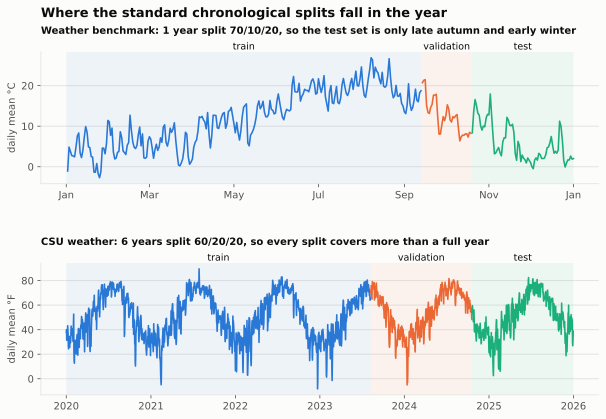

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), gridspec_kw={"hspace": 0.6})
panels = [
    (axes[0], weather, "T (degC)", "°C",
     "Weather benchmark: 1 year split 70/10/20, so the test set is only late autumn and early winter"),
    (axes[1], csu, "Temp", "°F",
     "CSU weather: 6 years split 60/20/20, so every split covers more than a full year"),
]
for ax, ts, channel, unit, title in panels:
    daily = ts.df[channel].resample("D").mean()          # daily means keep the plot readable
    for name, sl in split_slices(ts).items():
        start, stop = ts.timestamps[sl][0], ts.timestamps[sl][-1]
        part = daily.loc[start:stop]
        ax.plot(part.index, part, color=SPLIT_COLORS[name], lw=1.6)
        ax.axvspan(start, stop, color=SPLIT_COLORS[name], alpha=0.07, lw=0)
        ax.text(start + (stop - start) / 2, 1.0, name, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", fontsize=9.5, color=INK)
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold", pad=18)
    ax.set_ylabel(f"daily mean {unit}")
    tidy(ax)
axes[0].xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b"))
fig.suptitle("Where the standard chronological splits fall in the year",
             x=0.125, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.show()

The Weather benchmark is exactly the case you would worry about. It covers a single year, so a chronological split trains on January to mid-September and tests on mid-October to New Year: the model is scored almost entirely on a season it has seen only a little of, at the very start of the year. Our CSU data covers six years, so every split contains more than one full yearly cycle and the problem disappears.

## Measuring the shift

Zeng et al. show this directly in their appendix (Fig. 5): histograms of a channel's training and test values. We repeat it for three channels. As in our training code, values are normalized with the **training set's** mean and standard deviation, so the training histogram is centred at 0 with a spread of 1.

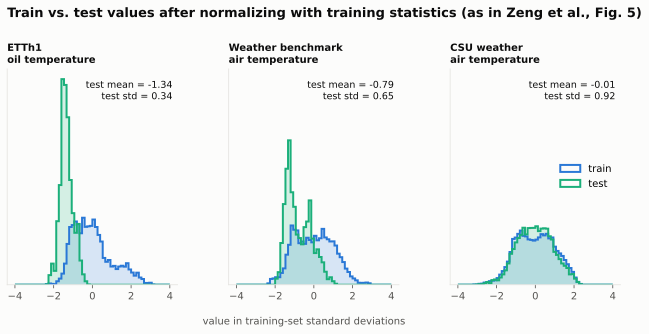

In [4]:
cases = [(etth1, "OT", "ETTh1\noil temperature"),
         (weather, "T (degC)", "Weather benchmark\nair temperature"),
         (csu, "Temp", "CSU weather\nair temperature")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9), sharey=True, gridspec_kw={"wspace": 0.3})
bins = np.linspace(-4, 4, 61)
for ax, (ts, channel, title) in zip(axes, cases):
    x = ts.channel(channel)
    s = split_slices(ts)
    mean, std = x[s["train"]].mean(), x[s["train"]].std()   # the scaler is fit on training data only
    for name in ("train", "test"):
        z = (x[s[name]] - mean) / std
        ax.hist(z, bins=bins, density=True, histtype="stepfilled", alpha=0.18,
                color=SPLIT_COLORS[name])
        ax.hist(z, bins=bins, density=True, histtype="step", lw=2,
                color=SPLIT_COLORS[name], label=name)
        if name == "test":
            ax.text(0.97, 0.95, f"test mean = {z.mean():+.2f}\ntest std = {z.std():.2f}",
                    transform=ax.transAxes, ha="right", va="top", fontsize=9.5, color=INK)
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold", pad=6)
    tidy(ax, grid=False)
    ax.set_yticks([])
axes[-1].legend(frameon=False, loc="center right")
fig.supxlabel("value in training-set standard deviations", fontsize=10, color=INK2, y=-0.04)
fig.suptitle("Train vs. test values after normalizing with training statistics (as in Zeng et al., Fig. 5)",
             x=0.125, y=1.1, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.show()

- **ETTh1:** the test values sit 1.34 training standard deviations below the training mean, and are much less spread out. This is the example Zeng et al. use to motivate NLinear (their Appendix D.1).
- **Weather benchmark:** the colder test period shifts the mean by −0.79.
- **CSU weather:** with full years in every split, train and test overlap almost exactly.

A model fitted to the training distribution is pushed towards predictions in the training range, so a shifted test set produces large errors even when the model has learned the right *shape* of the series.

## Why not shuffle?

The obvious fix is to shuffle, so that every split sees every season. The problem is overlap. The schematic compares the chronological split with three alternatives.

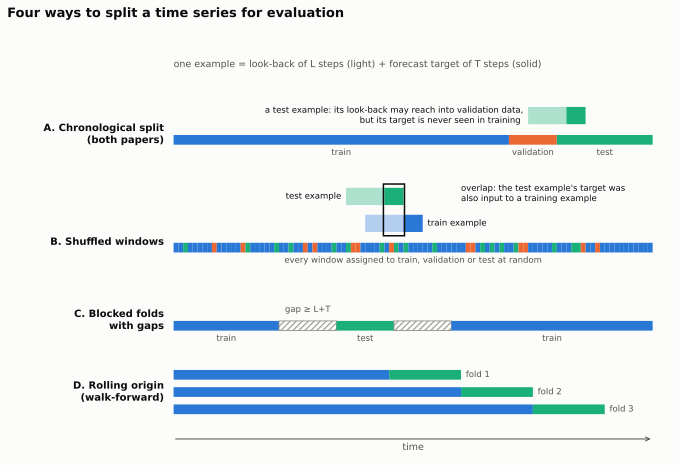

In [5]:
L_, T_ = 8, 4                   # look-back and horizon, in schematic time units
N_ = 100                        # length of the whole series

def window(ax, y, start, color, label=None):
    """Draw one training example: look-back (light) followed by its forecast target (solid)."""
    ax.add_patch(Rectangle((start, y - 0.16), L_, 0.32, color=color, alpha=0.35, lw=0))
    ax.add_patch(Rectangle((start + L_, y - 0.16), T_, 0.32, color=color, lw=0))
    if label:
        ax.text(start + (L_ + T_) / 2, y + 0.24, label, ha="center", va="bottom", fontsize=8.5, color=INK)

def block(ax, y, start, stop, name, text=True):
    if name == "gap":
        ax.add_patch(Rectangle((start, y - 0.09), stop - start, 0.18, facecolor=SURFACE,
                               edgecolor=MUTED, hatch="////", lw=0.8))
        return
    ax.add_patch(Rectangle((start, y - 0.09), stop - start, 0.18, color=SPLIT_COLORS[name], lw=0))
    if text:
        ax.text((start + stop) / 2, y - 0.16, name, ha="center", va="top", fontsize=8.5, color=INK2)

fig, ax = plt.subplots(figsize=(11, 7.2))
rows = {"A": 5.0, "B": 3.0, "C": 1.55, "D": 0.0}

# A. chronological split, as in both papers
y = rows["A"]
block(ax, y, 0, 70, "train"); block(ax, y, 70, 80, "validation"); block(ax, y, 80, 100, "test")
window(ax, y + 0.45, 74, SPLIT_COLORS["test"])
ax.text(73, y + 0.45, "a test example: its look-back may reach into validation data,\n"
        "but its target is never seen in training ", ha="right", va="center", fontsize=8.5, color=INK)
ax.text(-2, y + 0.1, "A. Chronological split\n(both papers)", ha="right", va="center", fontsize=10,
        fontweight="bold", color=INK)

# B. shuffled windows: a test target can sit inside a training example's look-back
y = rows["B"]
rng = np.random.default_rng(3)
names = rng.choice(["train", "validation", "test"], size=N_, p=[0.7, 0.1, 0.2])
names[36], names[40] = "test", "train"   # the two example windows drawn above
for start, name in enumerate(names):  # one thin bar per window start, coloured by its random split
    ax.add_patch(Rectangle((start, y - 0.09), 1, 0.18, color=SPLIT_COLORS[name], lw=0))
ax.text(50, y - 0.16, "every window assigned to train, validation or test at random", ha="center",
        va="top", fontsize=8.5, color=INK2)
window(ax, y + 0.45, 40, SPLIT_COLORS["train"])
ax.text(53, y + 0.45, "train example", ha="left", va="center", fontsize=8.5, color=INK)
window(ax, y + 0.95, 36, SPLIT_COLORS["test"])
ax.text(35, y + 0.95, "test example", ha="right", va="center", fontsize=8.5, color=INK)
ax.add_patch(Rectangle((43.8, y + 0.22), 4.4, 0.96, fill=False, edgecolor=INK, lw=1.5))
ax.text(60, y + 1.0, "overlap: the test example's target was\nalso input to a training example",
        ha="left", va="center", fontsize=8.5, color=INK)
ax.text(-2, y + 0.1, "B. Shuffled windows", ha="right", va="center", fontsize=10, fontweight="bold", color=INK)

# C. blocked folds with gaps
y = rows["C"]
edges = [(0, 22, "train"), (22, 34, "gap"), (34, 46, "test"), (46, 58, "gap"), (58, 100, "train")]
for a, b, name in edges:
    block(ax, y, a, b, name)
ax.text(28, y + 0.22, "gap ≥ L+T", ha="center", va="bottom", fontsize=8.5, color=INK2)
ax.text(-2, y + 0.1, "C. Blocked folds\nwith gaps", ha="right", va="center", fontsize=10,
        fontweight="bold", color=INK)

# D. rolling origin
for k, cut in enumerate([45, 60, 75]):
    yy = rows["D"] + 0.32 * (2 - k)
    block(ax, yy, 0, cut, "train", text=False)
    block(ax, yy, cut, cut + 15, "test", text=False)
    ax.text(cut + 16, yy, f"fold {k + 1}", ha="left", va="center", fontsize=8.5, color=INK2)
ax.text(-2, rows["D"] + 0.32, "D. Rolling origin\n(walk-forward)", ha="right", va="center", fontsize=10,
        fontweight="bold", color=INK)

ax.annotate("", xy=(100, -0.55), xytext=(0, -0.55),
            arrowprops=dict(arrowstyle="->", color=INK2, lw=1))
ax.text(50, -0.62, "time", ha="center", va="top", fontsize=9.5, color=INK2)
ax.text(0, 6.35, "one example = look-back of L steps (light) + forecast target of T steps (solid)",
        fontsize=9.5, color=INK2)
ax.set_xlim(-24, 104); ax.set_ylim(-0.9, 6.5); ax.set_axis_off()
fig.suptitle("Four ways to split a time series for evaluation", x=0.06, ha="left",
             fontsize=13, fontweight="bold", color=INK)
plt.show()

- **A. Chronological split (both papers).** A test example may use the end of the validation period as its look-back, but its target, the values being predicted, never appears in training. No leakage, but the test set covers only one stretch of time.
- **B. Shuffled windows.** Every window (one per start position, the thin bars) is assigned to a split at random, so every split sees every season. But windows overlap by up to $L+T-1$ steps, so a test target can be part of a training example. The model has effectively seen the answer, and the test score is too optimistic.
- **C. Blocked folds with gaps.** Split time into contiguous blocks, assign blocks rather than windows, and throw away a gap of at least $L+T$ steps on each side of every test block so no example crosses the boundary. Test blocks can now sit in any season. The cost is the discarded gaps, and every block must be longer than $L+T$ to hold even one example. With PatchTST's largest setting ($L = 512$, $T = 720$), each gap is 1,232 hourly steps, about 51 days.
- **D. Rolling origin (walk-forward).** Train on everything up to a cut-off, test on the next block, move the cut-off forward and repeat. Every fold respects time order, and averaging over folds covers several seasons. The cost is training one model per fold.

C and D are standard tools in classical forecasting, but the LTSF benchmarks use a single chronological split (A). That keeps results comparable across papers, at the cost of test scores that describe one particular period.

## What about preprocessing leaking information?

Any statistic computed from validation or test data and fed into training is leakage. The usual rules:

- Fit the normalization (mean and standard deviation) on the **training split only**, then apply it unchanged to validation and test. Our training code does this.
- Choose hyperparameters and stop training using **validation** scores; look at the **test** score once, at the end.
- *Per-window* normalization (NLinear, RevIN) is leakage-free by construction: each example is normalized using only its own look-back window, which the model is allowed to see at prediction time anyway.

That last point is how the papers deal with distribution shift. Rather than making the test set look like the training set, they make the model insensitive to the level and scale of each window, which is the subject of the next section.

## Coming next

- **Handling the shift inside the model:** NLinear (subtract the last value, add it back) and RevIN (normalize each window, then undo it), with a small Linear vs. NLinear experiment on ETTh1.